# Sub-etapa 1.2 (extensión) · Marcha en la vida diaria: registros de 3 días de LTMM

**Objetivo:** usar los registros principales de la base LTMM, en los que cada persona llevó el sensor en la espalda baja durante unos 3 días de su vida normal [Weiss et al., 2013]. A diferencia de las caminatas de laboratorio (1 minuto de pura marcha), aquí la marcha está mezclada con dormir, estar sentado o hacer otras cosas. Por eso este notebook:

1. **Encuentra los tramos en que la persona camina** (*walking bouts*), leyendo cada archivo de a pedazos.
2. **Comprueba el detector** con las caminatas de laboratorio, donde se sabe que la persona camina.
3. A cada tramo le aplica **las mismas funciones del notebook 01**: limpieza, detección de pasos y las 17 variables de marcha.
4. **Resume por persona** (mediana de sus tramos) y agrega variables de actividad, como cuántos minutos camina al día.
5. Hace el mismo análisis exploratorio que el notebook 01 y deja listas las tablas para los modelos.

**Productos:**

| Archivo | Contenido |
|---|---|
| `datos/procesados/vida_diaria/tramos/<registro>.csv` | Una fila por tramo de marcha de cada persona |
| `datos/procesados/vida_diaria/senales/<registro>.npz` | Señal de los tramos de marcha (hasta 10 min por persona, 50 Hz), para la LSTM |
| `datos/procesados/vida_diaria_variables.csv` | **Dataset de vida diaria:** una fila por persona |
| `datos/procesados/vida_diaria_modelo.csv` | Entrada de los modelos: variables de vida diaria no redundantes |
| `datos/procesados/combinado_modelo.csv` | Entrada de los modelos: variables de laboratorio + vida diaria |

**Antes de ejecutarlo:** ejecuta el notebook 01 (para la tabla de laboratorio). **Cuánto tarda:** procesar los ~71 registros puede tomar de 30 a 90 minutos. Cada persona se guarda apenas termina, así que si se interrumpe, al volver a ejecutarlo continúa donde quedó.

## 1. Configuración

In [1]:
import json
import platform
import re
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import wfdb
from scipy import signal, stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CARPETA_3D = RAIZ / "datos" / "crudos" / "Physionet"      # los .hea/.dat de 3 días
CARPETA_LABWALKS = RAIZ / "datos" / "crudos" / "LabWalks"  # para comprobar el detector
SALIDA = RAIZ / "datos" / "procesados"
VD = SALIDA / "vida_diaria"
FIGURAS = RAIZ / "figuras"
for c in (VD / "tramos", VD / "senales", FIGURAS):
    c.mkdir(parents=True, exist_ok=True)

# --- Lectura -----------------------------------------------------------------
BLOQUE_H = 1.0            # horas que se leen de una vez (así no se carga el archivo completo en memoria)

# --- Detector de marcha (sección 3) ------------------------------------------
VENTANA_DET_S = 5.0       # cada trozo que se evalúa
PASO_DET_S = 2.5          # los trozos se traslapan a la mitad
DE_MIN_G = 0.06           # movimiento mínimo del eje vertical (desviación estándar, en g)
BANDA_MARCHA_HZ = (0.6, 3.0)   # ritmo de los pasos
FRACCION_BANDA_MIN = 0.5  # al menos la mitad de la energía debe estar en el ritmo de los pasos
REGULARIDAD_MIN = 0.4     # los pasos deben repetirse (autocorrelación)
CALIBRAR = True           # relaja los 3 umbrales si las caminatas de laboratorio no los cumplen (sección 3.1)
PERCENTIL_CALIBRACION = 5 # el umbral deja pasar el 95 % de los trozos de marcha conocida
PISOS = {"de": 0.02, "fraccion": 0.25, "regularidad": 0.2}   # nunca se baja de estos valores
MIN_TRAMO_S = 30.0        # solo se usan tramos de marcha de al menos 30 s
RECORTE_TRAMO_S = 2.5     # se quitan los bordes de cada tramo (arranque y frenado)

# --- Limpieza y variables (iguales al notebook 01) ----------------------------
CORTE_RUIDO_HZ = 20.0
CORTE_PASOS_HZ = 3.0
LIMITES_INTERVALO = (0.5, 1.5)
MAX_PCT_DESCARTADOS = 20.0     # un tramo con más intervalos anómalos se descarta
MIN_TRAMOS_PERSONA = 5         # una persona con menos tramos válidos se excluye

# --- Señales para la LSTM -----------------------------------------------------
MAX_MIN_SENAL = 10.0      # minutos de marcha que se guardan por persona
DIEZMADO = 2              # 100 Hz -> 50 Hz

REPROCESAR = False        # True = vuelve a procesar aunque la persona ya esté guardada
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"No cae": "#1f5f99", "Cae": "#b03a2e"}

archivos = sorted(p.with_suffix("") for p in CARPETA_3D.glob("*.hea") if p.with_suffix(".dat").exists())
print(f"Registros de 3 días encontrados: {len(archivos)} en {CARPETA_3D}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | wfdb {wfdb.__version__}")

Registros de 3 días encontrados: 71 en F:\Practica_I\Práctica_investigación\Fuentes\Jupyter Notebook\proyecto-marcha\datos\crudos\Physionet
Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scipy 1.18.0 | wfdb 4.3.1


## 2. Los registros

Cada archivo dura unas 75 horas, a 100 Hz y con 6 canales: unos 160 millones de números, por eso pesa ~320 MB. Aquí solo se lee el encabezado (`.hea`) de cada uno, que es muy liviano. Los nombres siguen la misma regla que LabWalks: `CO` = no cae, `FL` = cae.

In [2]:
def nombres_estandar(nombres, unidades):
    # Igual que en el notebook 01: nombre fijo para cada canal
    claves_acc = [("acc_v", ("v-", "vert")), ("acc_ml", ("ml", "medio")), ("acc_ap", ("ap", "antero"))]
    claves_giro = [("giro_yaw", ("yaw",)), ("giro_pitch", ("pitch",)), ("giro_roll", ("roll",))]
    salida, n_acc, n_giro = [], 0, 0
    for nombre, unidad in zip(nombres, unidades):
        nl, u = nombre.lower(), str(unidad).strip().lower()
        if "acc" in nl or u in ("g", "m/s^2", "m/s2", "m/s/s"):
            clave = next((k for k, pal in claves_acc if any(x in nl for x in pal)), None) or f"acc_{n_acc + 1}"
            n_acc += 1
        else:
            clave = next((k for k, pal in claves_giro if any(x in nl for x in pal)), None) or f"giro_{n_giro + 1}"
            n_giro += 1
        while clave in salida:
            clave += "_b"
        salida.append(clave)
    return salida


def grupo_desde_nombre(nombre):
    n = nombre.lower()
    if n.startswith("co"):
        return "No cae", 0
    if n.startswith(("fl", "fo")):
        return "Cae", 1
    return "Desconocido", np.nan


filas = []
for ruta in archivos:
    h = wfdb.rdheader(str(ruta))
    grupo, cae = grupo_desde_nombre(h.record_name)
    datos = dict(c.split(":", 1) for c in (h.comments or []) if ":" in c)   # p. ej. "Age:75.17", "Sex:F"
    edad = pd.to_numeric(datos.get("Age", "").strip(), errors="coerce")
    filas.append({"registro": h.record_name, "clave": h.record_name[:5].lower(), "grupo": grupo, "cae": cae,
                  "edad": edad, "sexo": datos.get("Sex", "").strip() or np.nan,
                  "fs_hz": h.fs, "horas": h.sig_len / h.fs / 3600, "canales": ", ".join(h.sig_name)})
encabezados = pd.DataFrame(filas)
print(encabezados.groupby("grupo").agg(personas=("registro", "count"), horas_media=("horas", "mean")).round(1))
print("\nCanales:", encabezados["canales"].iloc[0])
print("Nombre en el notebook:", nombres_estandar(*[wfdb.rdheader(str(archivos[0])).__dict__[k] for k in ("sig_name", "units")]))
encabezados.head()

        personas  horas_media
grupo                        
Cae           31         69.1
No cae        40         70.0

Canales: v-acceleration, ml-acceleration, ap-acceleration, yaw-velocity, pitch-velocity, roll-velocity
Nombre en el notebook: ['acc_v', 'acc_ml', 'acc_ap', 'giro_yaw', 'giro_pitch', 'giro_roll']


,registro,clave,grupo,cae,edad,sexo,fs_hz,horas,canales
0,CO001,co001,No cae,0,75.17,F,100,47.615828,"v-acceleration, ml-acceleration, ap-accelerati..."
1,CO002,co002,No cae,0,82.92,M,100,74.999936,"v-acceleration, ml-acceleration, ap-accelerati..."
2,CO003,co003,No cae,0,75.34,F,100,74.999936,"v-acceleration, ml-acceleration, ap-accelerati..."
3,CO004,co004,No cae,0,69.18,F,100,74.999936,"v-acceleration, ml-acceleration, ap-accelerati..."
4,CO005,co005,No cae,0,77.62,M,100,72.418325,"v-acceleration, ml-acceleration, ap-accelerati..."


## 3. Detector de tramos de marcha

La señal se recorre en trozos de 5 s (traslapados a la mitad). Un trozo se considera **marcha** si cumple tres condiciones a la vez:

| Condición | Qué revisa | Por qué |
|---|---|---|
| Movimiento | La desviación estándar del eje vertical es mayor a 0,06 g | Descarta el reposo y el sueño |
| Ritmo de pasos | Al menos la mitad de la energía está entre 0,6 y 3 Hz | La marcha tiene un ritmo de 1 a 2 pasos por segundo |
| Repetición | La autocorrelación tiene un pico de al menos 0,4 entre 0,3 y 1,2 s | Los pasos se repiten; un movimiento irregular (cocinar, ordenar) no |

Los trozos de marcha seguidos se unen en **tramos**, y solo se usan los de **al menos 30 s**, para que tengan suficientes pasos para medir la variabilidad. Los valores de los umbrales están al inicio del notebook y se comprueban en la sección 3.1.

In [3]:
def pasabajo(x, fs, fc, orden=4):
    b, a = signal.butter(orden, fc / (fs / 2), btype="low")
    return signal.filtfilt(b, a, x, axis=0)


def medidas_trozos(v, fs):
    # Para cada trozo de 5 s: movimiento (de), fracción de energía en el ritmo de pasos, regularidad e inicio
    L, paso = int(VENTANA_DET_S * fs), int(PASO_DET_S * fs)
    if len(v) < L:
        vacio = np.array([])
        return vacio, vacio, vacio, np.array([], int)
    trozos = np.lib.stride_tricks.sliding_window_view(v, L)[::paso]
    trozos = trozos - trozos.mean(axis=1, keepdims=True)
    de = trozos.std(axis=1)
    espectro = np.abs(np.fft.rfft(trozos, n=2 * L, axis=1)) ** 2
    f = np.fft.rfftfreq(2 * L, 1 / fs)
    banda = espectro[:, (f >= BANDA_MARCHA_HZ[0]) & (f <= BANDA_MARCHA_HZ[1])].sum(axis=1)
    total = espectro[:, (f >= 0.3) & (f <= 15)].sum(axis=1) + 1e-12
    ac = np.fft.irfft(espectro, axis=1)[:, :L]
    ac = ac / (ac[:, :1] + 1e-12)
    rango = slice(int(0.3 * fs), int(1.2 * fs))
    regularidad = ac[:, rango].max(axis=1)
    return de, banda / total, regularidad, np.arange(len(trozos)) * paso


def marcar_marcha(v, fs):
    # Devuelve, para cada trozo de 5 s, si es marcha (True/False) y dónde empieza (en muestras)
    de, fraccion, regularidad, inicios = medidas_trozos(v, fs)
    es_marcha = (de > DE_MIN_G) & (fraccion > FRACCION_BANDA_MIN) & (regularidad > REGULARIDAD_MIN)
    return es_marcha, inicios


def tramos_desde_marcas(es_marcha, inicios, fs):
    # Une trozos de marcha seguidos en tramos (inicio, fin) en muestras
    L, tramos, actual = int(VENTANA_DET_S * fs), [], None
    for m, i in zip(es_marcha, inicios):
        if m and actual is None:
            actual = [i, i + L]
        elif m:
            actual[1] = i + L
        elif actual is not None:
            tramos.append(tuple(actual))
            actual = None
    if actual is not None:
        tramos.append(tuple(actual))
    return [(a, b) for a, b in tramos if (b - a) / fs >= MIN_TRAMO_S]


def detectar_tramos(ruta):
    # Lee el registro de a bloques (solo el eje vertical) y devuelve sus tramos de marcha
    h = wfdb.rdheader(str(ruta))
    iv = nombres_estandar(h.sig_name, h.units).index("acc_v")
    fs, n = h.fs, h.sig_len
    bloque, solape = int(BLOQUE_H * 3600 * fs), int((VENTANA_DET_S - PASO_DET_S) * fs)
    marcas, inicios = [], []
    a = 0
    while a < n:
        b = min(n, a + bloque + solape)
        v = wfdb.rdrecord(str(ruta), sampfrom=a, sampto=b, channels=[iv]).p_signal[:, 0]
        m, i = marcar_marcha(np.nan_to_num(v), fs)
        dentro = (i + a) < a + bloque          # evita contar dos veces los trozos del solape
        marcas.append(m[dentro])
        inicios.append(i[dentro] + a)
        a += bloque
    return tramos_desde_marcas(np.concatenate(marcas), np.concatenate(inicios), fs), h

### 3.1 Comprobación del detector con las caminatas de laboratorio

En LabWalks se sabe que la persona camina todo el tiempo, así que un buen detector debería marcar como marcha casi toda cada caminata. Además, las caminatas sirven para **calibrar** el detector: si un umbral deja fuera más del 5 % de los trozos de laboratorio, se baja hasta el percentil 5 de esos trozos (así deja pasar el 95 % de la marcha conocida), sin bajar de un mínimo. La calibración solo relaja los umbrales, nunca los endurece. Esto adapta el detector a la marcha de adultos mayores, más lenta y menos regular que la de un adulto joven. Si los umbrales cambian, la sección 5 vuelve a procesar todos los registros. Después de calibrar, cada tramo igual debe pasar el control de calidad de la sección 4 (pasos detectables y pocos intervalos anómalos), que es un segundo filtro contra movimientos que no son marcha. Además se revisa lo contrario en los registros de 3 días: qué parte del día queda marcada como marcha (en adultos mayores suele ser una fracción pequeña del día).

Umbrales iniciales: movimiento > 0.060 g, ritmo de pasos > 0.50, repetición > 0.40
  Trozos de laboratorio que cumplen cada condición: movimiento 93 %, ritmo de pasos 64 %, repetición 91 %, marcha 62 %

Umbrales calibrados: movimiento > 0.054 g, ritmo de pasos > 0.29, repetición > 0.30
  Trozos de laboratorio que cumplen cada condición: movimiento 95 %, ritmo de pasos 95 %, repetición 95 %, marcha 89 %

Medidas de los trozos de laboratorio (percentiles 5, 25 y 50):
         de  fraccion  regularidad
0.05  0.054     0.286        0.296
0.25  0.147     0.455        0.568
0.50  0.184     0.570        0.678
Caminatas de laboratorio revisadas: 73
Porcentaje del tiempo detectado como marcha: mediana 100 %, mínimo 0 %
Caminatas con menos de 80 % detectado: 8
Peores caminatas: [{'registro': 'fl019_base', 'pct_marcha': 0.0}, {'registro': 'fl015_base', 'pct_marcha': 17.0}, {'registro': 'fl020_base', 'pct_marcha': 25.0}, {'registro': 'fl008_base', 'pct_marcha': 53.0}, {'registro': 'fl035_base', 'p

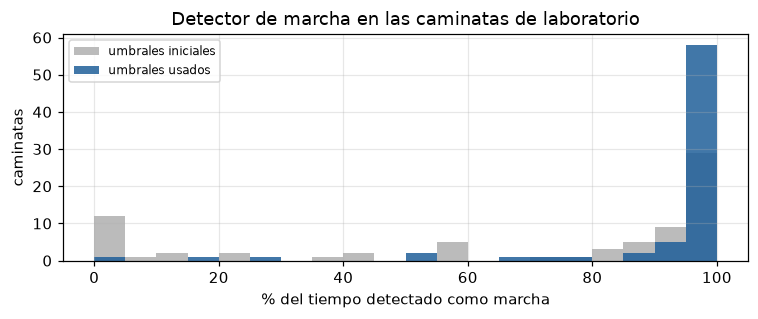

In [4]:
# Medidas de cada trozo de 5 s de las caminatas de laboratorio (se sabe que es marcha)
trozos_lab = []
for ruta in sorted(p.with_suffix("") for p in CARPETA_LABWALKS.rglob("*.hea")):
    r = wfdb.rdrecord(str(ruta))
    iv = nombres_estandar(r.sig_name, r.units).index("acc_v")
    v = r.p_signal[int(3 * r.fs):-int(3 * r.fs), iv]       # sin arranque ni frenado, como en el notebook 01
    de, fr, rg, _ = medidas_trozos(np.nan_to_num(v), r.fs)
    trozos_lab.append(pd.DataFrame({"registro": r.record_name, "de": de, "fraccion": fr, "regularidad": rg}))
trozos_lab = pd.concat(trozos_lab, ignore_index=True) if trozos_lab else pd.DataFrame()


def revisar(titulo):
    # % de cada caminata detectado como marcha, y qué condición falla más
    ok = pd.DataFrame({"movimiento": trozos_lab["de"] > DE_MIN_G,
                       "ritmo de pasos": trozos_lab["fraccion"] > FRACCION_BANDA_MIN,
                       "repetición": trozos_lab["regularidad"] > REGULARIDAD_MIN})
    ok["marcha"] = ok.all(axis=1)
    print(f"{titulo}: movimiento > {DE_MIN_G:.3f} g, ritmo de pasos > {FRACCION_BANDA_MIN:.2f}, "
          f"repetición > {REGULARIDAD_MIN:.2f}")
    print("  Trozos de laboratorio que cumplen cada condición: " +
          ", ".join(f"{c} {100 * ok[c].mean():.0f} %" for c in ok.columns))
    return ok.assign(registro=trozos_lab["registro"]).groupby("registro")["marcha"].mean().mul(100) \
        .rename("pct_marcha").reset_index()


if len(trozos_lab):
    antes = revisar("Umbrales iniciales")
    if CALIBRAR:
        q = PERCENTIL_CALIBRACION
        DE_MIN_G = min(DE_MIN_G, max(PISOS["de"], float(np.percentile(trozos_lab["de"], q))))
        FRACCION_BANDA_MIN = min(FRACCION_BANDA_MIN, max(PISOS["fraccion"], float(np.percentile(trozos_lab["fraccion"], q))))
        REGULARIDAD_MIN = min(REGULARIDAD_MIN, max(PISOS["regularidad"], float(np.percentile(trozos_lab["regularidad"], q))))
        print()
        revision = revisar("Umbrales calibrados")
    else:
        revision = antes
    print()
    print("Medidas de los trozos de laboratorio (percentiles 5, 25 y 50):")
    print(trozos_lab[["de", "fraccion", "regularidad"]].quantile([0.05, 0.25, 0.5]).round(3).to_string())
    (VD / "umbrales.json").write_text(json.dumps({"de": DE_MIN_G, "fraccion": FRACCION_BANDA_MIN,
                                                   "regularidad": REGULARIDAD_MIN}, indent=2))
else:
    revision = pd.DataFrame()
if len(revision):
    print(f"Caminatas de laboratorio revisadas: {len(revision)}")
    print(f"Porcentaje del tiempo detectado como marcha: mediana {revision['pct_marcha'].median():.0f} %, "
          f"mínimo {revision['pct_marcha'].min():.0f} %")
    print(f"Caminatas con menos de 80 % detectado: {(revision['pct_marcha'] < 80).sum()}")
    print(f"Peores caminatas: {revision.nsmallest(5, 'pct_marcha').round(0).to_dict('records')}")
    fig, eje = plt.subplots(figsize=(7, 3))
    if CALIBRAR:
        eje.hist(antes["pct_marcha"], bins=20, range=(0, 100), color="#bbbbbb", label="umbrales iniciales")
    eje.hist(revision["pct_marcha"], bins=20, range=(0, 100), color="#1f5f99", alpha=0.85,
             label="umbrales usados")
    eje.legend(fontsize=8)
    eje.set(title="Detector de marcha en las caminatas de laboratorio", xlabel="% del tiempo detectado como marcha",
            ylabel="caminatas")
    fig.tight_layout()
    fig.savefig(FIGURAS / "vida_diaria_detector_labwalks.png", dpi=150)
else:
    print("No se encontraron caminatas de laboratorio para comprobar el detector.")

## 4. Variables de cada tramo

Son **las mismas funciones del notebook 01**: limpieza (filtro de 20 Hz y sin gravedad), detección de pasos, descarte de intervalos anómalos y las 17 variables. Un tramo se descarta si se le descarta más del 20 % de sus intervalos entre pasos, igual que una caminata de laboratorio.

In [5]:
def detectar_pasos(v, fs):
    suave = pasabajo(v, fs, CORTE_PASOS_HZ)
    picos, _ = signal.find_peaks(suave, distance=int(0.3 * fs), prominence=0.3 * np.std(suave))
    return picos, suave


def autocorr(x):
    x = x - x.mean()
    ac = signal.correlate(x, x, mode="full", method="fft")[len(x) - 1:]
    return ac / ac[0]


def regularidad(v, fs):
    ac = autocorr(v)
    lags = np.arange(len(ac)) / fs
    picos, _ = signal.find_peaks(ac)
    candidatos = picos[(lags[picos] > 0.25) & (lags[picos] < 1.0)]
    if len(candidatos) == 0:
        return np.nan, np.nan, np.nan
    p1 = candidatos[np.argmax(ac[candidatos])]
    zona = picos[(picos > 1.5 * p1) & (picos < 2.5 * p1)]
    if len(zona) == 0:
        return ac[p1], np.nan, np.nan
    p2 = zona[np.argmax(ac[zona])]
    return ac[p1], ac[p2], ac[p1] / ac[p2]


def espectro(v, fs):
    f, p = signal.welch(v, fs=fs, nperseg=min(len(v), int(10 * fs)), nfft=8192)
    banda = (f >= 0.5) & (f <= 3.0)
    i = np.argmax(np.where(banda, p, 0))
    mitad = p[i] / 2
    izq = i
    while izq > 0 and p[izq] > mitad:
        izq -= 1
    der = i
    while der < len(p) - 1 and p[der] > mitad:
        der += 1
    return f[i], p[i], f[der] - f[izq]


def intervalos_validos(picos, fs):
    t = np.diff(picos) / fs
    if len(t) < 3:
        return t, np.array([]), np.nan
    ok = (t > LIMITES_INTERVALO[0] * np.median(t)) & (t < LIMITES_INTERVALO[1] * np.median(t))
    zancadas = (t[:-1] + t[1:])[ok[:-1] & ok[1:]]
    return t[ok], zancadas, 100 * (1 - ok.mean())


def variables(df, fs):
    v = df["acc_v"].to_numpy()
    picos, _ = detectar_pasos(v, fs)
    t_paso, t_zancada, pct_descartado = intervalos_validos(picos, fs)
    d1, d2, sim = regularidad(v, fs)
    f_dom, amp_dom, ancho = espectro(v, fs)
    cv = lambda x: 100 * np.std(x, ddof=1) / np.mean(x) if len(x) > 2 else np.nan
    fila = {"n_pasos": len(picos), "pct_intervalos_descartados": pct_descartado,
            "cadencia_pasos_min": 60 / t_paso.mean() if len(t_paso) else np.nan,
            "tiempo_paso_s": t_paso.mean() if len(t_paso) else np.nan, "cv_tiempo_paso_pct": cv(t_paso),
            "tiempo_zancada_s": t_zancada.mean() if len(t_zancada) else np.nan,
            "cv_tiempo_zancada_pct": cv(t_zancada), "regularidad_paso": d1, "regularidad_zancada": d2,
            "simetria": sim, "frec_dominante_hz": f_dom, "amplitud_dominante": amp_dom, "ancho_pico_hz": ancho}
    for col in df.columns.drop("tiempo_s"):
        fila[f"rms_{col}"] = np.sqrt(np.mean((df[col] - df[col].mean()) ** 2))
    return fila


def limpiar_tramo(x, nombres, fs):
    n = int(RECORTE_TRAMO_S * fs)
    x = pasabajo(x[n:-n], fs, CORTE_RUIDO_HZ)
    df = pd.DataFrame(x, columns=nombres)
    df["acc_v"] -= df["acc_v"].mean()
    df.insert(0, "tiempo_s", np.arange(len(df)) / fs)
    return df

## 5. Procesar todos los registros

Para cada persona: se detectan sus tramos, se leen solo esos pedazos del archivo, se calculan las variables y se guarda un archivo por persona. También se guardan hasta 10 minutos de sus tramos válidos a 50 Hz para la LSTM, empezando por los más largos. **Este paso es el que más tarda.**

In [6]:
def procesar(ruta):
    tramos, h = detectar_tramos(ruta)
    nombres, fs = nombres_estandar(h.sig_name, h.units), h.fs
    filas, senales, guardado = [], {}, 0.0
    for k, (a, b) in enumerate(sorted(tramos, key=lambda t: t[0] - t[1])):   # del más largo al más corto
        x = np.nan_to_num(wfdb.rdrecord(str(ruta), sampfrom=a, sampto=b).p_signal)
        df = limpiar_tramo(x, nombres, fs)
        fila = {"registro": h.record_name, "tramo": k + 1, "inicio_h": a / fs / 3600, "duracion_s": (b - a) / fs,
                **variables(df, fs)}
        fila["valido"] = bool(fila["pct_intervalos_descartados"] <= MAX_PCT_DESCARTADOS and fila["n_pasos"] >= 10)
        filas.append(fila)
        if fila["valido"] and guardado < MAX_MIN_SENAL * 60:
            senales[f"tramo_{k + 1}"] = df.drop(columns="tiempo_s").to_numpy(np.float32)[::DIEZMADO]
            guardado += len(df) / fs
    tabla = pd.DataFrame(filas)
    if tabla.empty:
        tabla = pd.DataFrame(columns=["registro", "tramo", "inicio_h", "duracion_s", "valido"])
    tabla.to_csv(VD / "tramos" / f"{h.record_name}.csv", index=False, float_format="%.5f")
    np.savez_compressed(VD / "senales" / f"{h.record_name}.npz", canales=np.array(nombres), **senales)
    return len(tramos)


# Si los umbrales cambiaron desde la última vez, hay que volver a procesar a todos
actuales = {"de": DE_MIN_G, "fraccion": FRACCION_BANDA_MIN, "regularidad": REGULARIDAD_MIN}
archivo_usados = VD / "umbrales_usados.json"
usados = json.loads(archivo_usados.read_text()) if archivo_usados.exists() else None
if usados is None or any(abs(usados[k] - actuales[k]) > 1e-9 for k in actuales):
    print("Umbrales nuevos: se procesan todos los registros de nuevo.")
    for viejo in list((VD / "tramos").glob("*.csv")) + list((VD / "senales").glob("*.npz")):
        viejo.unlink()

inicio = time.time()
for i, ruta in enumerate(archivos, start=1):
    if not REPROCESAR and (VD / "tramos" / f"{ruta.name}.csv").exists():
        continue
    t0 = time.time()
    n = procesar(ruta)
    print(f"{i:2d}/{len(archivos)} {ruta.name}: {n} tramos de marcha | {time.time() - t0:.0f} s "
          f"(total {(time.time() - inicio) / 60:.1f} min)")
archivo_usados.write_text(json.dumps(actuales, indent=2))
print("Listo: todos los registros están procesados.")

Umbrales nuevos: se procesan todos los registros de nuevo.
 1/71 CO001: 113 tramos de marcha | 5 s (total 0.1 min)
 2/71 CO002: 165 tramos de marcha | 9 s (total 0.2 min)
 3/71 CO003: 13 tramos de marcha | 5 s (total 0.3 min)
 4/71 CO004: 93 tramos de marcha | 6 s (total 0.4 min)
 5/71 CO005: 89 tramos de marcha | 6 s (total 0.5 min)
 6/71 CO006: 60 tramos de marcha | 6 s (total 0.6 min)
 7/71 CO007: 47 tramos de marcha | 5 s (total 0.7 min)
 8/71 CO008: 76 tramos de marcha | 6 s (total 0.8 min)
 9/71 CO009: 73 tramos de marcha | 6 s (total 0.9 min)
10/71 CO010: 36 tramos de marcha | 5 s (total 1.0 min)
11/71 CO011: 111 tramos de marcha | 6 s (total 1.1 min)
12/71 CO012: 117 tramos de marcha | 7 s (total 1.2 min)
13/71 CO013: 25 tramos de marcha | 5 s (total 1.3 min)
14/71 CO014: 57 tramos de marcha | 4 s (total 1.3 min)
15/71 CO015: 31 tramos de marcha | 5 s (total 1.4 min)
16/71 CO016: 32 tramos de marcha | 5 s (total 1.5 min)
17/71 CO017: 65 tramos de marcha | 6 s (total 1.6 min)
18

## 6. Resumen por persona

Cada persona queda en una fila: la **mediana** de cada variable en todos sus tramos válidos (la mediana no se deja arrastrar por un tramo raro), más variables de actividad diaria. Se excluyen las personas con menos de 5 tramos válidos.

In [7]:
tablas = [pd.read_csv(p) for p in sorted((VD / "tramos").glob("*.csv"))]
sin_marcha = [t for t in tablas if t.empty]      # personas sin ningún tramo de marcha de 30 s o más
tramos = pd.concat([t for t in tablas if not t.empty], ignore_index=True)   # (las tablas vacías volverían texto los números)
print(f"Registros sin ningún tramo de marcha detectado: {len(sin_marcha)}")
tramos = tramos[tramos["registro"].isin(encabezados["registro"])]
validos = tramos[tramos["valido"] == True]
VARIABLES_MARCHA = ["cadencia_pasos_min", "tiempo_paso_s", "cv_tiempo_paso_pct", "tiempo_zancada_s",
                    "cv_tiempo_zancada_pct", "regularidad_paso", "regularidad_zancada", "simetria",
                    "frec_dominante_hz", "amplitud_dominante", "ancho_pico_hz"] + \
                   sorted(c for c in tramos.columns if c.startswith("rms_"))

resumen = validos.groupby("registro")[VARIABLES_MARCHA].median()
actividad = tramos.groupby("registro").agg(tramos_detectados=("tramo", "count"),
                                            minutos_marcha=("duracion_s", lambda d: d.sum() / 60),
                                            duracion_media_tramo_s=("duracion_s", "mean"))
actividad["tramos_validos"] = validos.groupby("registro").size()
actividad = actividad.fillna({"tramos_validos": 0})
vida = encabezados[["registro", "clave", "grupo", "cae", "horas"]].merge(actividad, on="registro", how="left") \
    .merge(resumen, on="registro", how="left")
vida["minutos_marcha_dia"] = vida["minutos_marcha"] / (vida["horas"] / 24)

vida["excluir"] = vida["tramos_validos"].fillna(0) < MIN_TRAMOS_PERSONA
print(f"Personas: {len(vida)} | excluidas por tener menos de {MIN_TRAMOS_PERSONA} tramos válidos: "
      f"{int(vida['excluir'].sum())} {vida.loc[vida['excluir'], 'registro'].tolist()}")
print(f"Tramos de marcha detectados: {len(tramos)} | válidos: {len(validos)} "
      f"({100 * len(validos) / max(len(tramos), 1):.0f} %)")
vida = vida[~vida["excluir"]].drop(columns="excluir").reset_index(drop=True)
vida.to_csv(SALIDA / "vida_diaria_variables.csv", index=False, float_format="%.5f")
vida.groupby("grupo")[["horas", "minutos_marcha_dia", "tramos_validos", "duracion_media_tramo_s"]].median().round(1)

Registros sin ningún tramo de marcha detectado: 0
Personas: 71 | excluidas por tener menos de 5 tramos válidos: 1 ['FL035']
Tramos de marcha detectados: 3905 | válidos: 3741 (96 %)


,horas,minutos_marcha_dia,tramos_validos,duracion_media_tramo_s
grupo,,,,
Cae,73.1,22.6,49.0,75.2
No cae,74.4,28.1,46.5,81.2


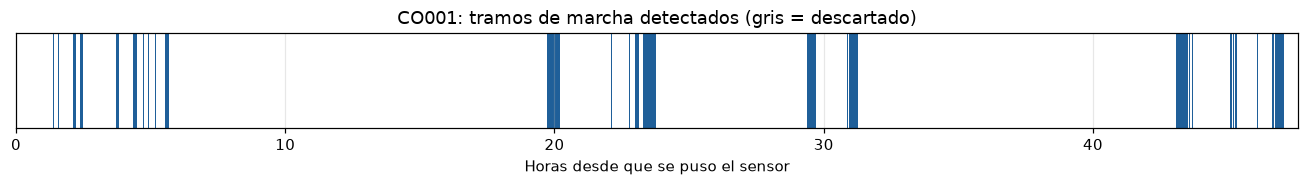

In [8]:
# Un ejemplo: dónde camina una persona a lo largo del registro
ejemplo = vida["registro"].iloc[0]
t_ej = tramos[tramos["registro"] == ejemplo]
fig, eje = plt.subplots(figsize=(12, 1.8))
for _, r in t_ej.iterrows():
    eje.axvspan(r["inicio_h"], r["inicio_h"] + r["duracion_s"] / 3600,
                color="#1f5f99" if r["valido"] else "#bbbbbb", lw=0)
eje.set(xlim=(0, encabezados.set_index("registro").loc[ejemplo, "horas"]), yticks=[],
        xlabel="Horas desde que se puso el sensor", title=f"{ejemplo}: tramos de marcha detectados (gris = descartado)")
fig.tight_layout()
fig.savefig(FIGURAS / "vida_diaria_tramos_ejemplo.png", dpi=150)

## 7. Análisis exploratorio de la vida diaria

El mismo análisis del notebook 01 (Mann-Whitney, tamaño del efecto r y corrección de Holm), ahora con las variables de vida diaria y de actividad.

In [9]:
def holm(p):
    p = np.asarray(p)
    orden = np.argsort(p)
    ajustado = np.empty_like(p)
    acumulado = 0
    for k, i in enumerate(orden):
        acumulado = max(acumulado, min(1, (len(p) - k) * p[i]))
        ajustado[i] = acumulado
    return ajustado


VARIABLES_VD = VARIABLES_MARCHA + ["minutos_marcha_dia", "duracion_media_tramo_s"]
filas = []
for v in VARIABLES_VD:
    a = vida.loc[vida["grupo"] == "No cae", v].dropna()
    b = vida.loc[vida["grupo"] == "Cae", v].dropna()
    if len(a) < 3 or len(b) < 3:
        continue
    u, p = stats.mannwhitneyu(b, a, alternative="two-sided")
    filas.append({"variable": v, "mediana_no_cae": a.median(), "mediana_cae": b.median(),
                  "efecto_r": 2 * u / (len(a) * len(b)) - 1, "p": p})
comparacion_vd = pd.DataFrame(filas)
comparacion_vd["p_holm"] = holm(comparacion_vd["p"])
comparacion_vd = comparacion_vd.reindex(comparacion_vd["efecto_r"].abs().sort_values(ascending=False).index)
comparacion_vd.to_csv(SALIDA / "vida_diaria_comparacion_grupos.csv", index=False)
comparacion_vd.round(4)

,variable,mediana_no_cae,mediana_cae,efecto_r,p,p_holm
16,rms_giro_yaw,22.3869,21.0030,-0.3283,0.0197,0.3743
9,amplitud_dominante,0.0801,0.0438,-0.3150,0.0253,0.4551
13,rms_acc_v,0.1748,0.1608,-0.2633,0.0616,1.0000
4,cv_tiempo_zancada_pct,6.1219,6.7713,0.2567,0.0685,1.0000
11,rms_acc_ap,0.1357,0.1219,-0.2450,0.0821,1.0000
14,rms_giro_pitch,14.2667,13.0835,-0.2367,0.0931,1.0000
15,rms_giro_roll,14.0214,12.9975,-0.2183,0.1214,1.0000
12,rms_acc_ml,0.1279,0.1213,-0.1933,0.1705,1.0000
18,duracion_media_tramo_s,81.1661,75.1756,-0.1683,0.2330,1.0000
2,cv_tiempo_paso_pct,9.3862,9.7467,0.1650,0.2424,1.0000


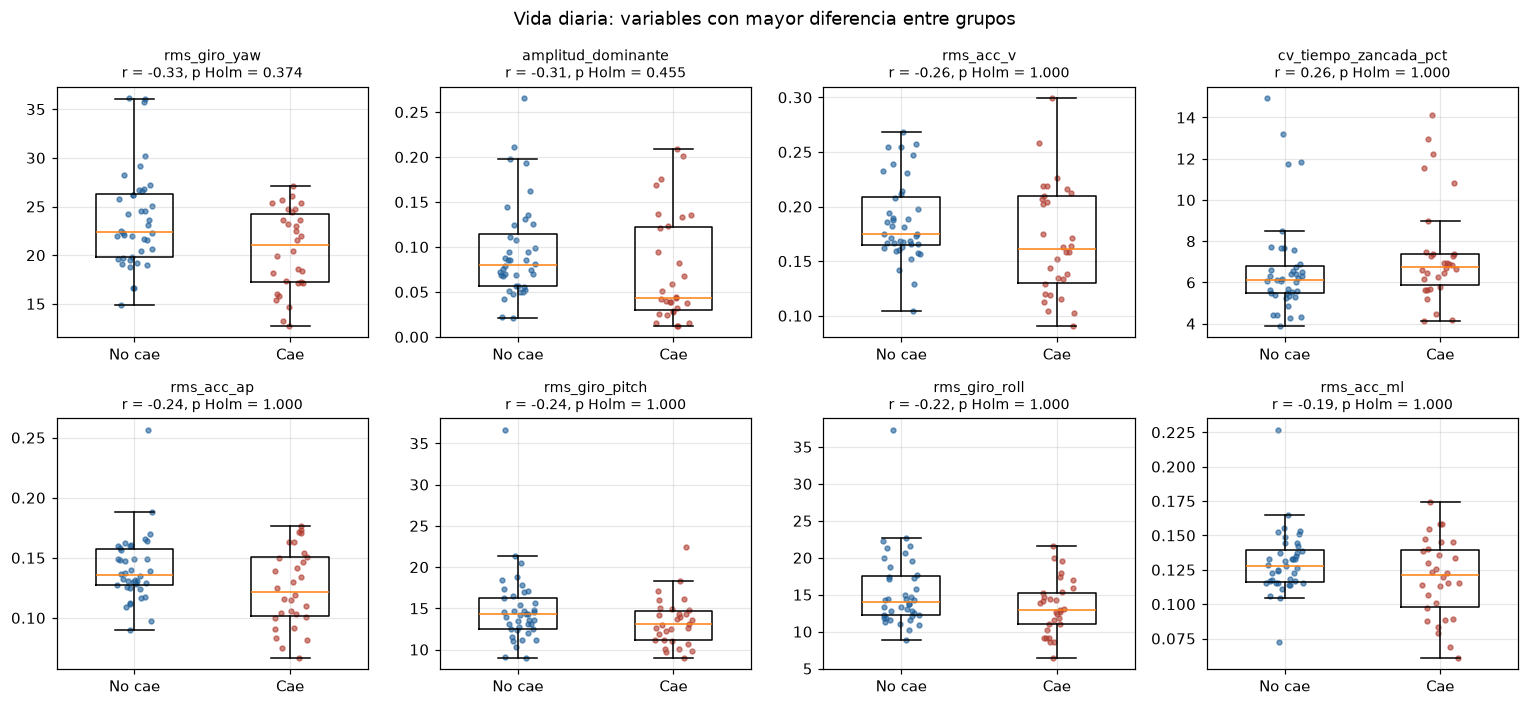

In [10]:
principales = comparacion_vd["variable"].head(8).tolist()
fig, ejes = plt.subplots(2, 4, figsize=(14, 6.5))
rng = np.random.default_rng(SEMILLA)
for eje, v in zip(ejes.flat, principales):
    datos = [vida.loc[vida["grupo"] == g, v].dropna() for g in ("No cae", "Cae")]
    eje.boxplot(datos, widths=0.5, showfliers=False)
    eje.set_xticks([1, 2], ["No cae", "Cae"])
    for i, (g, d) in enumerate(zip(("No cae", "Cae"), datos), start=1):
        eje.scatter(i + rng.uniform(-0.12, 0.12, len(d)), d, s=10, alpha=0.6, color=COLORES[g])
    fila = comparacion_vd.set_index("variable").loc[v]
    eje.set_title(f"{v}\nr = {fila['efecto_r']:.2f}, p Holm = {fila['p_holm']:.3f}", fontsize=9)
fig.suptitle("Vida diaria: variables con mayor diferencia entre grupos")
fig.tight_layout()
fig.savefig(FIGURAS / "vida_diaria_variables_por_grupo.png", dpi=150)

### 7.1 ¿Se parece la marcha del laboratorio a la de la vida diaria?

Para las personas que están en ambas bases se compara cada variable medida en el laboratorio con la misma variable en la vida diaria (correlación de Spearman). Una correlación baja significa que la caminata de 1 minuto en el laboratorio no refleja bien cómo camina la persona en su día a día.

In [11]:
lab = pd.read_csv(SALIDA / "labwalks_variables.csv")
lab["clave"] = lab["registro"].str[:5].str.lower()
ambos = lab.merge(vida, on="clave", suffixes=("_lab", "_vd"))
filas = [{"variable": v, "personas": int(ambos[[f"{v}_lab", f"{v}_vd"]].dropna().shape[0]),
          "correlacion": stats.spearmanr(ambos[f"{v}_lab"], ambos[f"{v}_vd"], nan_policy="omit")[0]}
         for v in VARIABLES_MARCHA if f"{v}_lab" in ambos and f"{v}_vd" in ambos]
lab_vs_vd = pd.DataFrame(filas).sort_values("correlacion", ascending=False)
print(f"Personas con laboratorio y vida diaria: {len(ambos)}")
lab_vs_vd.round(2)

Personas con laboratorio y vida diaria: 62


,variable,personas,correlacion
13,rms_acc_v,62,0.72
15,rms_giro_roll,62,0.72
9,amplitud_dominante,62,0.69
8,frec_dominante_hz,62,0.69
16,rms_giro_yaw,62,0.64
0,cadencia_pasos_min,62,0.62
1,tiempo_paso_s,62,0.62
11,rms_acc_ap,62,0.61
3,tiempo_zancada_s,62,0.61
7,simetria,62,0.52


## 8. Tablas para los modelos

Igual que en el notebook 01: se recorren las variables en orden y se descarta una variable si su correlación de Spearman con alguna ya elegida es mayor a 0,9. Se crean dos tablas:

* `vida_diaria_modelo.csv`: solo vida diaria.
* `combinado_modelo.csv`: las variables elegidas de laboratorio (terminan en `_lab`) y de vida diaria (terminan en `_vd`), para las personas que están en ambas bases.

En los notebooks 03 y 04 se elige cuál usar con el parámetro `DATOS`.

In [12]:
def elegir(tabla, columnas, umbral=0.9):
    corr = tabla[columnas].corr(method="spearman")
    elegidas = []
    for v in columnas:
        if all(abs(corr.loc[v, e]) <= umbral for e in elegidas):
            elegidas.append(v)
    return elegidas


elegidas_vd = elegir(vida, VARIABLES_VD)
modelo_vd = vida[["registro", "clave", "grupo", "cae"] + elegidas_vd]
modelo_vd.to_csv(SALIDA / "vida_diaria_modelo.csv", index=False, float_format="%.5f")
print(f"Vida diaria: {len(modelo_vd)} personas y {len(elegidas_vd)} variables -> vida_diaria_modelo.csv")

lab_modelo = pd.read_csv(SALIDA / "labwalks_modelo.csv")
lab_modelo["clave"] = lab_modelo["registro"].str[:5].str.lower()
vars_lab = [c for c in lab_modelo.columns if c not in ("registro", "grupo", "cae", "clave")]
combinado = lab_modelo.rename(columns={v: f"{v}_lab" for v in vars_lab}).merge(
    modelo_vd.drop(columns=["registro", "grupo", "cae"]).rename(columns={v: f"{v}_vd" for v in elegidas_vd}),
    on="clave")
combinado.to_csv(SALIDA / "combinado_modelo.csv", index=False, float_format="%.5f")
print(f"Combinado: {len(combinado)} personas y {len(vars_lab) + len(elegidas_vd)} variables -> combinado_modelo.csv")

Vida diaria: 70 personas y 16 variables -> vida_diaria_modelo.csv
Combinado: 62 personas y 30 variables -> combinado_modelo.csv


## 9. Resumen para el informe

In [13]:
e = comparacion_vd.set_index("variable")
sig = e[e["p_holm"] < 0.05].index.tolist()
fmt = lambda x, d=1: f"{x:.{d}f}".replace(".", ",")
print(f"* Registros: {len(encabezados)} de unas {fmt(encabezados['horas'].median())} horas; {len(vida)} personas con al menos "
      f"{MIN_TRAMOS_PERSONA} tramos válidos ({int((vida['cae'] == 0).sum())} no caen, {int((vida['cae'] == 1).sum())} caen).")
if len(revision):
    print(f"* Detector: en las caminatas de laboratorio marcó como marcha una mediana de "
          f"{fmt(revision['pct_marcha'].median(), 0)} % del tiempo.")
print(f"* Tramos: {len(tramos)} detectados de al menos {MIN_TRAMO_S:g} s, {len(validos)} válidos; mediana de "
      f"{fmt(vida['minutos_marcha_dia'].median())} minutos de marcha al día por persona.")
print(f"* Variables con mayor diferencia: " + ", ".join(
    f"{v} (r = {fmt(e.loc[v, 'efecto_r'], 2)}; p Holm = {fmt(e.loc[v, 'p_holm'], 3)})" for v in e.index[:3]) +
      f". Significativas tras Holm: {', '.join(sig) if sig else 'ninguna'}.")
print(f"* Tablas para los modelos: vida diaria ({len(elegidas_vd)} variables) y combinado ({len(combinado)} personas).")

* Registros: 71 de unas 74,0 horas; 70 personas con al menos 5 tramos válidos (40 no caen, 30 caen).
* Detector: en las caminatas de laboratorio marcó como marcha una mediana de 100 % del tiempo.
* Tramos: 3905 detectados de al menos 30 s, 3741 válidos; mediana de 22,8 minutos de marcha al día por persona.
* Variables con mayor diferencia: rms_giro_yaw (r = -0,33; p Holm = 0,374), amplitud_dominante (r = -0,31; p Holm = 0,455), rms_acc_v (r = -0,26; p Holm = 1,000). Significativas tras Holm: ninguna.
* Tablas para los modelos: vida diaria (16 variables) y combinado (62 personas).
